# Sensor Contribution and Range Sensitivity Study

**Study ID:** `sensor_contribution_sensitivity_v1`  
**Stage:** Follow-up to `sensor_realism_validation_v1`. All numerical sensor parameters remain uncalibrated.

Questions:
1. Which measurements does each modality actually provide, and how do distance/motion change availability?
2. Does a frozen, observation-driven driving policy change behavior when we remove sensing modalities?
3. Do conclusions depend on assuming RGB has a longer range than event cameras?

No new policy is trained. We retain the lightweight object-level sensor model. Run with the project's `.venv` kernel. This is a diagnostic study, not a real-world hardware ranking.

In [1]:
from pathlib import Path
import sys, copy, json, hashlib
from datetime import datetime
from zoneinfo import ZoneInfo
from importlib.metadata import version
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "environments/sensor_highway/env.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from environments.sensor_highway import ExperimentConfig
from algorithms.sensor_agent import LinearExpectedSarsa
from experiments.sensor_study_helpers import MODALITIES, modality_mask, measure_sensor, frozen_policy_rollout
STUDY_ID = "sensor_contribution_sensitivity_v1"
SEED = 42
TRIALS = 300
VALIDATION_SEEDS = [100004, 100005, 100006]  # Different from the prior 100000–100003 tests.
WEATHER = ["clear", "fog"]
BASE_RUN = PROJECT_ROOT / "runs/training/time_completion_20261101_111935_114914"
if not (BASE_RUN / "always_on_agent.npz").exists():
    raise FileNotFoundError("Set BASE_RUN to the saved short-route Expected SARSA run.")
config = ExperimentConfig.load(BASE_RUN / "config.json")
agent = LinearExpectedSarsa.load(BASE_RUN / "always_on_agent.npz")
assert agent.modes == ("all_on",)
frozen_weights = agent.weights.copy()
print("Interpreter:", sys.executable)
print("Frozen driver:", BASE_RUN)
print("Task:", config.reward.route_distance_m, "m; deadline:", config.highway["duration"], "s")


Interpreter: .venv/bin/python
Frozen driver: runs/training/time_completion_20261101_111935_114914
Task: 300 m; deadline: 16 s


## 1. Model structure versus external evidence

| Reference | What it supports | What it does not establish for this project |
|---|---|---|
| [openMSL object-level perception model](https://github.com/openMSL/sl-1-3-object-based-generic-perception-object-model) | Object-level radar/LiDAR models with configurable field of view, occlusion, range and noise are an existing approach | Our numerical settings are calibrated |
| [DSEC driving dataset](https://dsec.ifi.uzh.ch/) | Synchronized event cameras, color cameras, and LiDAR in varied illumination provide relevant comparison material | A universal RGB/event range ordering, or device switching energy |
| [Seeing Through Fog](https://www.cs.princeton.edu/~fheide/AdverseWeatherFusion/) | Multimodal driving and controlled fog-chamber observations can inform weather modeling | A direct mapping from our severity scalar to measured visibility |

These are methodological/data references, not fitted calibration targets. No detector has been evaluated on those datasets here. Detection performance depends on both hardware and perception processing. The evidence register in the baseline notebook remains the place to record hardware-specific sources and conditions.


## 2. Information supplied by one forward sensor per modality

Measure bearing, range, and radial relative-velocity errors in clear weather with one unobstructed target. Ego speed is 25 m/s; relative target speeds are -10, -2, and 0 m/s. Distances are independent snapshots, not a continuous trajectory.

The internal `_capture` method isolates measurement generation; acquisition timing, warm-up, fusion, and energy are excluded here. False positives are disabled so each detection belongs to the single target. **Missing measurements stay NaN, never zero error.** Errors are conditional on a detection: always read them with detection fraction/count. Binomial SE describes sampling variation inside this model, not uncertainty about real hardware.

RGB/event provide bearing only in this implementation; radar adds range/velocity; LiDAR adds range. This is our current observation contract, not a universal restriction on real perception systems.

,kind,range_setting_m,distance_m,relative_speed_m_s,trials,detections,detection_fraction,binomial_se,bearing_rmse_deg,range_rmse_m,velocity_rmse_m_s
0,rgb,100,20,-10,300,275,0.9167,0.0160,1.0161,NaN,NaN
3,rgb,100,40,-10,300,239,0.7967,0.0232,0.9756,NaN,NaN
6,rgb,100,80,-10,300,95,0.3167,0.0269,1.0010,NaN,NaN
9,rgb,100,120,-10,300,0,0.0000,0.0000,NaN,NaN,NaN
12,event,60,20,-10,300,256,0.8533,0.0204,1.4257,NaN,NaN
15,event,60,40,-10,300,46,0.1533,0.0208,1.5756,NaN,NaN
18,event,60,80,-10,300,0,0.0000,0.0000,NaN,NaN,NaN
21,event,60,120,-10,300,0,0.0000,0.0000,NaN,NaN,NaN
24,radar,150,20,-10,300,281,0.9367,0.0141,2.9538,0.9976,0.5216
27,radar,150,40,-10,300,268,0.8933,0.0178,3.0663,0.9882,0.5325


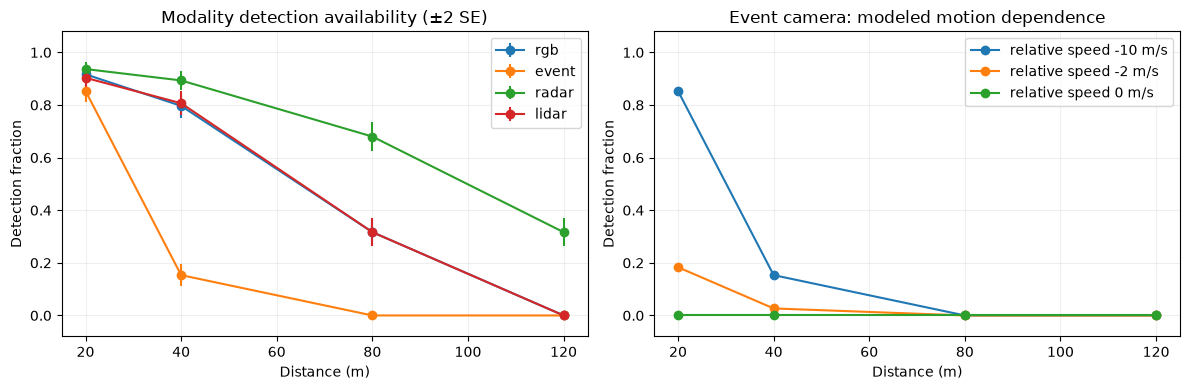

In [2]:
representatives = [copy.deepcopy(next(s for s in config.sensors if s.kind == k)) for k in MODALITIES]
information_results = pd.DataFrame([measure_sensor(s, distance, speed, TRIALS, SEED)
    for s in representatives for distance in [20, 40, 80, 120] for speed in [-10, -2, 0]])
assert information_results.loc[information_results.kind.isin(["rgb", "event"]), "range_rmse_m"].isna().all()
assert information_results.loc[information_results.kind != "radar", "velocity_rmse_m_s"].isna().all()
display(information_results[information_results.relative_speed_m_s == -10].round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for kind, group in information_results[information_results.relative_speed_m_s == -10].groupby("kind", sort=False):
    axes[0].errorbar(group.distance_m, group.detection_fraction, yerr=2 * group.binomial_se,
                     marker="o", label=kind)
event = information_results[information_results.kind == "event"]
for speed, group in event.groupby("relative_speed_m_s"):
    axes[1].plot(group.distance_m, group.detection_fraction, marker="o", label=f"relative speed {speed} m/s")
axes[0].set(title="Modality detection availability (±2 SE)", xlabel="Distance (m)", ylabel="Detection fraction")
axes[1].set(title="Event camera: modeled motion dependence", xlabel="Distance (m)", ylabel="Detection fraction")
for ax in axes:
    ax.legend(); ax.grid(alpha=.2); ax.set_ylim(-.08, 1.08)
plt.tight_layout(); plt.show()


## 3. Optical range assumptions

Sweep the same 40, 60, 100, and 140 m cutoff for RGB and event cameras at matched geometry and relative speed -10 m/s. All other modality parameters retain their defaults. These values are sensitivity settings, **not recommended hardware ranges**. The existing detection curve reaches zero at the cutoff.

This answers how much the simulated ordering depends on the hardcoded range advantage. It does not isolate all other modality differences or determine the correct real-world cutoff.

kind                        event    rgb
range_setting_m distance_m              
40              20          0.723  0.723
                40          0.000  0.000
                80          0.000  0.000
                120         0.000  0.000
60              20          0.853  0.853
                40          0.153  0.510
                80          0.000  0.000
                120         0.000  0.000
100             20          0.917  0.917
                40          0.217  0.797
                80          0.027  0.317
                120         0.000  0.000
140             20          0.937  0.937
                40          0.230  0.890
                80          0.057  0.647
                120         0.017  0.220

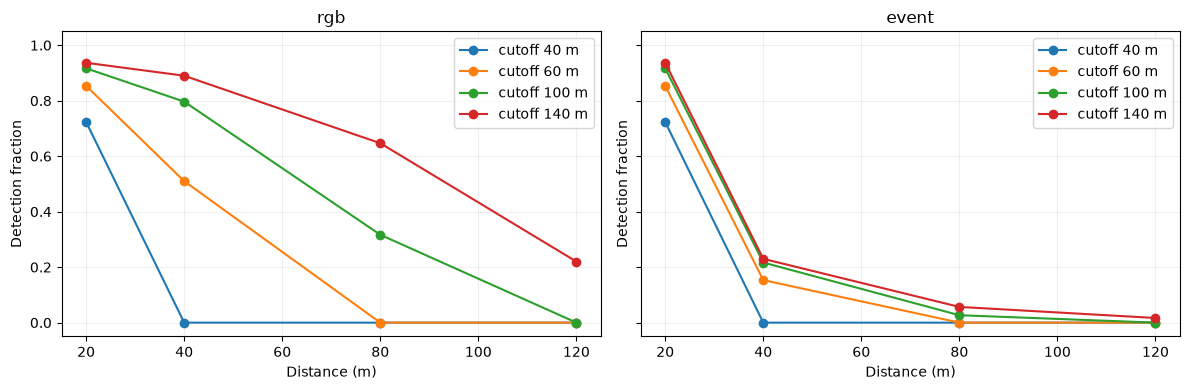

In [3]:
range_records = []
for sensor in representatives[:2]:
    for cutoff in [40, 60, 100, 140]:
        trial_sensor = copy.deepcopy(sensor)
        trial_sensor.range_m = cutoff
        for distance in [20, 40, 80, 120]:
            range_records.append(measure_sensor(trial_sensor, distance, -10, TRIALS, SEED))
range_results = pd.DataFrame(range_records)
display(range_results.pivot_table(index=["range_setting_m", "distance_m"], columns="kind", values="detection_fraction").round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, kind in zip(axes, ["rgb", "event"]):
    for cutoff, group in range_results[range_results.kind == kind].groupby("range_setting_m"):
        ax.plot(group.distance_m, group.detection_fraction, marker="o", label=f"cutoff {cutoff:g} m")
    ax.set(title=kind, xlabel="Distance (m)", ylabel="Detection fraction", ylim=(-.05, 1.05))
    ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.show()


## 4. Frozen-driver sensor ablations

Use the saved short-route always-on driver with **frozen weights and zero exploration**. It still receives observations and chooses driving actions; we override only the active sensor mask. Compare all sensors, each modality alone, each modality removed, and all-off.

The short-route model keeps this diagnostic practical: 300 m, 16 s deadline. All conditions use matched validation traffic seeds and weather. Modality-only conditions enable all installed sensors of that kind; coverage and power differ by design. Since the driver was trained with all sensors on, ablations introduce observation-distribution shifts. Results measure **this driver's dependence on sensing**, not each modality's best achievable performance.

A driver that chooses the same actions regardless of sensing will show similar safety outcomes even when measurement quality differs. That is a policy limitation to investigate. Grid support and uncertainty are model proxies, not ground-truth perception accuracy.

In [4]:
CONDITIONS = ["all_on", "off", *MODALITIES, *("without_" + k for k in MODALITIES)]
mask_inventory = pd.DataFrame([{"condition": name,
    "active_sensors": int(modality_mask(config, name).sum()),
    "nominal_power_w": sum(s.power_w if on else s.standby_w
                           for s, on in zip(config.sensors, modality_mask(config, name)))}
    for name in CONDITIONS])
display(mask_inventory)
ablation_records, action_histories = [], []
for weather in WEATHER:
    trial_config = copy.deepcopy(config)
    trial_config.weather.preset = weather
    for seed in VALIDATION_SEEDS:
        for condition in CONDITIONS:
            metrics, history = frozen_policy_rollout(trial_config, agent, condition, seed)
            ablation_records.append(metrics)
            action_histories.append(history.assign(condition=condition, seed=seed, weather=weather))
    print("Ablations finished:", weather, flush=True)
ablation_results = pd.DataFrame(ablation_records)
action_results = pd.concat(action_histories, ignore_index=True)
assert np.array_equal(agent.weights, frozen_weights)
def summarize(table, by):
    return table.groupby(by, sort=False).agg(
        episodes=("seed", "count"), completion_fraction=("completed", "mean"),
        crash_fraction=("crashed", "mean"), successful_finish_s=("completion_time_s", "mean"),
        distance_m=("distance_m", "mean"), mean_power_w=("mean_power_w", "mean"),
        supported_fraction=("mean_supported_fraction", "mean"),
        uncertainty_proxy=("mean_uncertainty_proxy", "mean"))
ablation_summary = summarize(ablation_results, ["condition"])
display(ablation_summary.round(3))
# Compare full driving sequences with all-on on the same seed/weather.
sequence_records = []
for (weather, seed), trial in action_results.groupby(["weather", "seed"]):
    baseline = trial[trial.condition == "all_on"].drive.tolist()
    for condition in CONDITIONS:
        sequence_records.append({"weather": weather, "seed": seed, "condition": condition,
            "identical_full_drive_sequence": trial[trial.condition == condition].drive.tolist() == baseline})
sequence_comparison = pd.DataFrame(sequence_records)
display(sequence_comparison.groupby("condition", sort=False).identical_full_drive_sequence.mean()
        .rename("fraction_of_trials_with_identical_actions_to_all_on").to_frame())


,condition,active_sensors,nominal_power_w
0,all_on,18,123.0
1,off,0,1.8
2,rgb,8,65.0
3,event,8,25.0
4,radar,1,11.7
5,lidar,1,26.7
6,without_rgb,10,59.8
7,without_event,10,99.8
8,without_radar,17,113.1
9,without_lidar,17,98.1


Ablations finished: clear


Ablations finished: fog


,episodes,completion_fraction,crash_fraction,successful_finish_s,distance_m,mean_power_w,supported_fraction,uncertainty_proxy
condition,,,,,,,,
all_on,6,1.000,0.000,15.0,305.331,123.0,0.019,0.965
off,6,0.667,0.333,13.0,240.623,1.8,0.000,1.000
rgb,6,1.000,0.000,15.0,305.331,65.0,0.010,0.988
event,6,1.000,0.000,15.0,305.331,25.0,0.002,0.999
radar,6,1.000,0.000,15.0,305.331,11.7,0.013,0.969
lidar,6,1.000,0.000,15.0,305.331,26.7,0.002,0.993
without_rgb,6,1.000,0.000,15.0,305.331,59.8,0.014,0.956
without_event,6,1.000,0.000,15.0,305.331,99.8,0.018,0.966
without_radar,6,1.000,0.000,15.0,305.331,113.1,0.011,0.987


,fraction_of_trials_with_identical_actions_to_all_on
condition,
all_on,1.0
off,0.0
rgb,1.0
event,1.0
radar,1.0
lidar,1.0
without_rgb,1.0
without_event,1.0
without_radar,1.0


## 5. Does range ordering affect the frozen driver's behavior?

Retain all-on sensing and vary only the RGB/event range settings. Use the same frozen driver and validation seeds. The original profile reuses the all-on results above rather than repeating the simulator runs. This is a within-simulator sensitivity check, not calibration. No reward weight or learning setting changes.

In [5]:
RANGE_PROFILES = {"original_rgb100_event60": {"rgb": 100, "event": 60},
                  "equal60": {"rgb": 60, "event": 60},
                  "equal100": {"rgb": 100, "event": 100},
                  "swapped_rgb60_event100": {"rgb": 60, "event": 100}}
profile_records = ablation_results[ablation_results.condition == "all_on"].assign(
    profile="original_rgb100_event60").to_dict("records")
profile_configs = {}
for profile, ranges in RANGE_PROFILES.items():
    trial_config = copy.deepcopy(config)
    for sensor in trial_config.sensors:
        if sensor.kind in ranges:
            sensor.range_m = ranges[sensor.kind]
    trial_config.validate()
    profile_configs[profile] = copy.deepcopy(trial_config)
    if profile == "original_rgb100_event60":
        continue
    for weather in WEATHER:
        trial_config.weather.preset = weather
        for seed in VALIDATION_SEEDS:
            metrics, _ = frozen_policy_rollout(trial_config, agent, "all_on", seed)
            profile_records.append({"profile": profile, **metrics})
    print("Range profile finished:", profile, flush=True)
profile_results = pd.DataFrame(profile_records)
profile_summary = summarize(profile_results, ["profile"])
display(profile_summary.round(3))
assert np.array_equal(agent.weights, frozen_weights)


Range profile finished: equal60


Range profile finished: equal100


Range profile finished: swapped_rgb60_event100


,episodes,completion_fraction,crash_fraction,successful_finish_s,distance_m,mean_power_w,supported_fraction,uncertainty_proxy
profile,,,,,,,,
original_rgb100_event60,6,1.0,0.0,15.0,305.331,123.0,0.019,0.965
equal60,6,1.0,0.0,15.0,305.331,123.0,0.016,0.959
equal100,6,1.0,0.0,15.0,305.331,123.0,0.020,0.964
swapped_rgb60_event100,6,1.0,0.0,15.0,305.331,123.0,0.018,0.960


## 6. Record conclusions and remaining evidence

Read the actual results above before editing these notes:

- **Measurement availability:** Which modality adds range or closing velocity? Read detection counts with conditional errors.
- **Motion dependence:** Does the event-camera proxy suppress useful information when relative motion is small? This rule still requires external evidence.
- **Range assumption:** Does equalizing or reversing ranges change detection ordering and policy outcomes?
- **Policy dependence:** Do driving sequences change under ablation? If not, avoid attributing successful driving to better sensing.
- **Uncertainty:** Six validation trials per condition are exploratory. New traffic seeds, independent training seeds, and held-out calibration measurements are still needed.
- **Missing checks:** False-positive rates, occlusion/side coverage, lighting, and hardware startup/power remain separate validation tasks. These diagnostics do not cover them all.

External datasets need an explicit detector/evaluation protocol to derive empirical detection probabilities. Do not copy a hardware maximum range into a reliable vehicle-detection range without supporting conditions.

In [6]:
RESEARCH_NOTES = {
    "empirical_calibration": "pending; no external measurements fitted",
    "measurement_conclusions": "Review information_results and range_results",
    "policy_conclusions": "Review ablation_summary and sequence_comparison",
    "range_sensitivity_conclusions": "Review profile_summary",
    "next_evidence": "Hardware-specific optics/resolution and detection curves under documented conditions"
}
output = PROJECT_ROOT / "runs/sensor_studies" / ("sensor_contribution_study_" +
    datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S_%f"))
output.mkdir(parents=True, exist_ok=False)
config.save(output / "base_config.json")
for profile, profile_config in profile_configs.items():
    profile_config.save(output / f"config_{profile}.json")
for name, table in {"information": information_results, "range_sensitivity": range_results,
    "mask_inventory": mask_inventory, "ablations": ablation_results, "ablation_summary": ablation_summary.reset_index(),
    "driving_actions": action_results, "sequence_comparison": sequence_comparison,
    "range_profiles": profile_results, "range_profile_summary": profile_summary.reset_index()}.items():
    table.to_csv(output / f"{name}.csv", index=False)
source_paths = [BASE_RUN / "always_on_agent.npz", BASE_RUN / "config.json",
    PROJECT_ROOT / "experiments/sensor_study_helpers.py", PROJECT_ROOT / "environments/sensor_highway/sensors.py",
    PROJECT_ROOT / "environments/sensor_highway/weather.py"]
metadata = {"study_id": STUDY_ID, "base_run": str(BASE_RUN.relative_to(PROJECT_ROOT)),
    "seed": SEED, "trials": TRIALS, "validation_seeds": VALIDATION_SEEDS,
    "weather": WEATHER, "conditions": CONDITIONS, "range_profiles": RANGE_PROFILES,
    "diagnostic_overrides": {"capture_trials_false_positive_rate_hz": 0},
    "training": "none; frozen always-on Expected SARSA driver", "research_notes": RESEARCH_NOTES,
    "sources_sha256": {str(p.relative_to(PROJECT_ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_paths},
    "package_versions": {k: version(k) for k in ["numpy", "pandas", "matplotlib", "gymnasium", "highway-env"]}}
(output / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved study:", output)


Saved study: runs/sensor_studies/sensor_contribution_study_20261101_124523_070422


## First recorded results

Recorded run: `sensor_contribution_study_20261101_124523_070422`.
These results describe this saved run; reruns may differ if configuration/models change.

- All-on completed 6/6 matched validation trials with zero crashes.
- Each individual modality and every leave-one-modality-out condition also completed 6/6.
  All of these produced the same full driving sequence as all-on on each matched trial.
- All-off completed 4/6 and crashed in 2/6, with different driving sequences on all six trials.
- Equal 60 m, equal 100 m, original RGB100/event60, and reversed RGB60/event100 profiles
  all completed 6/6 in 15 s on average. Map support/uncertainty changed, but aggregate driving
  outcomes did not. These proxies do not establish perception accuracy.

Interpretation: this frozen short-route driver is insensitive to many sensing changes in
these scenarios. Its response to all-off could depend on sensor-status features as well as
missing detections; this experiment does not separate those causes. No modality is proven
superior, and the optical cutoffs remain uncalibrated. Distribution shift and the six-trial
sample limit the conclusions. A useful next diagnostic would separate sensor-status inputs
from delivered measurement information and add controlled closing-vehicle/lane-change
scenarios before using driving outcomes to rank sensing configurations.
